In [10]:
# Cell 1: Setup Graphviz for PDA and CFG Parse Tree Visualization
!apt-get install graphviz libgraphviz-dev pkg-config -y > /dev/null 2>&1
!pip install graphviz > /dev/null 2>&1

import graphviz
from IPython.display import display

print("Setup completed successfully! Ready for Task 3 Simulation.")

Setup completed successfully! Ready for Task 3 Simulation.


In [11]:
# Cell 2: Generic Pushdown Automaton (PDA) Simulation Engine
class PushdownAutomaton:
    def __init__(self, states, input_alphabet, stack_alphabet, transitions, start_state, start_stack, accept_states, accept_by='final_state'):
        self.states = states
        self.input_alphabet = input_alphabet
        self.stack_alphabet = stack_alphabet
        self.transitions = transitions
        self.start_state = start_state
        self.start_stack = start_stack
        self.accept_states = accept_states
        self.accept_by = accept_by  # 'final_state' or 'empty_stack'

    def process(self, input_string):
        state = self.start_state
        stack = [self.start_stack]
        trace = [(state, input_string, "".join(stack))]

        for i, char in enumerate(input_string):
            remaining_input = input_string[i+1:]
            top_stack = stack[-1] if stack else None

            # Lookup transition key: (state, char, top_of_stack)
            key = (state, char, top_stack)
            if key in self.transitions:
                next_state, stack_op = self.transitions[key]
                state = next_state
                if stack_op == 'POP':
                    stack.pop()
                elif isinstance(stack_op, tuple) and stack_op[0] == 'PUSH':
                    stack.append(stack_op[1])
                elif stack_op == 'NOOP':
                    pass
            else:
                state = 'q_trap'
                trace.append((state, remaining_input, "".join(stack) if stack else "ε"))
                return False, trace

            trace.append((state, remaining_input, "".join(stack) if stack else "ε"))

        # Check epsilon transitions after input is consumed
        top_stack = stack[-1] if stack else None
        while (state, 'ε', top_stack) in self.transitions:
            next_state, stack_op = self.transitions[(state, 'ε', top_stack)]
            state = next_state
            if stack_op == 'POP':
                stack.pop()
            elif isinstance(stack_op, tuple) and stack_op[0] == 'PUSH':
                stack.append(stack_op[1])
            top_stack = stack[-1] if stack else None
            trace.append((state, "", "".join(stack) if stack else "ε"))

        if self.accept_by == 'final_state':
            is_accepted = (state in self.accept_states)
        else:
            is_accepted = (len(stack) == 0)

        return is_accepted, trace

    def run_tests(self, test_cases, case_name=""):
        print(f"\n{'='*25} {case_name} Test Results {'='*25}")
        for string, expected in test_cases:
            accepted, trace = self.process(string)
            status = "ACCEPTED" if accepted else "REJECTED"
            res = "PASS" if accepted == expected else "FAIL"
            disp = string if string != "" else "ε (empty)"
            print(f"Input: {disp!r:<20} | Status: {status:<8} | Final State: {trace[-1][0]:<8} | [{res}]")


========================= Case Study 1: Balanced Parentheses Test Results =========================
Input: '()'                 | Status: ACCEPTED | Final State: q_acc    | [PASS]
Input: '(())'               | Status: ACCEPTED | Final State: q_acc    | [PASS]
Input: '()()'               | Status: ACCEPTED | Final State: q_acc    | [PASS]
Input: '((()()))'           | Status: ACCEPTED | Final State: q_acc    | [PASS]
Input: 'ε (empty)'          | Status: ACCEPTED | Final State: q_acc    | [PASS]
Input: '('                  | Status: REJECTED | Final State: q0       | [PASS]
Input: ')'                  | Status: REJECTED | Final State: q_trap   | [PASS]
Input: '())('               | Status: REJECTED | Final State: q_trap   | [PASS]
Input: '((())'              | Status: REJECTED | Final State: q0       | [PASS]
Input: '())'                | Status: REJECTED | Final State: q_trap   | [PASS]

--- Detailed Stack Trace for Accepted String '(())' ---
Step 0: |- (State: q0    , Remaining Input

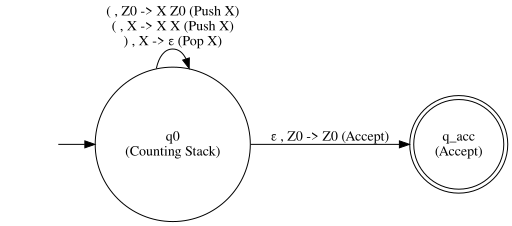

In [12]:
# Cell 3: Case Study 1 - Balanced Parentheses Delimiter Checker
# CFG: S -> (S) | SS | ε
# PDA pushes 'X' on '(', pops 'X' on ')'

def build_parentheses_pda():
    states = {'q0', 'q_acc', 'q_trap'}
    input_alphabet = {'(', ')'}
    stack_alphabet = {'Z0', 'X'}
    transitions = {
        ('q0', '(', 'Z0'): ('q0', ('PUSH', 'X')),
        ('q0', '(', 'X'):  ('q0', ('PUSH', 'X')),
        ('q0', ')', 'X'):  ('q0', 'POP'),
        ('q0', 'ε', 'Z0'): ('q_acc', 'NOOP'),
    }
    return PushdownAutomaton(states, input_alphabet, stack_alphabet, transitions, 'q0', 'Z0', {'q_acc'})

pda_paren = build_parentheses_pda()

# 5 Accepted & 5 Rejected Test Cases
paren_test_cases = [
    # 5 Accepted
    ("()", True),
    ("(())", True),
    ("()()", True),
    ("((()()))", True),
    ("", True),            # Empty string ε is balanced
    # 5 Rejected
    ("(", False),          # Unclosed bracket
    (")", False),          # Premature close bracket
    ("())(", False),       # Unbalanced sequence
    ("((())", False),      # Missing close bracket
    ("())", False)         # Extra close bracket
]

pda_paren.run_tests(paren_test_cases, "Case Study 1: Balanced Parentheses")

# Detailed Stack Moves (Instantaneous Description) for '(())'
print("\n--- Detailed Stack Trace for Accepted String '(())' ---")
_, trace_paren = pda_paren.process("(())")
for step, (st, rem, stk) in enumerate(trace_paren):
    rem_disp = rem if rem != "" else "ε"
    print(f"Step {step}: |- (State: {st:<6}, Remaining Input: {rem_disp!r:<6}, Stack: {stk})")

# State Transition Diagram for Parentheses PDA
dot_paren = graphviz.Digraph('Balanced_Parentheses_PDA', format='png')
dot_paren.attr(rankdir='LR')
dot_paren.node('', shape='none')
dot_paren.node('q0', shape='circle', label='q0\n(Counting Stack)')
dot_paren.node('q_acc', shape='doublecircle', label='q_acc\n(Accept)')

dot_paren.edge('', 'q0')
dot_paren.edge('q0', 'q0', label=" ( , Z0 -> X Z0 (Push X)\n ( , X -> X X (Push X)\n ) , X -> ε (Pop X)")
dot_paren.edge('q0', 'q_acc', label=" ε , Z0 -> Z0 (Accept)")

display(dot_paren)


=================== Case Study 2: Arithmetic Syntax Validation ===================
Expression: 'id'                 | Status: ACCEPTED | [PASS]
Expression: 'id+id'              | Status: ACCEPTED | [PASS]
Expression: 'id*id+id'           | Status: ACCEPTED | [PASS]
Expression: '(id+id)*id'         | Status: ACCEPTED | [PASS]
Expression: 'id*(id+id*id)'      | Status: ACCEPTED | [PASS]
Expression: 'id+'                | Status: REJECTED | [PASS]
Expression: '+id'                | Status: REJECTED | [PASS]
Expression: 'id*+id'             | Status: REJECTED | [PASS]
Expression: '(id+id'             | Status: REJECTED | [PASS]
Expression: 'id id'              | Status: REJECTED | [PASS]


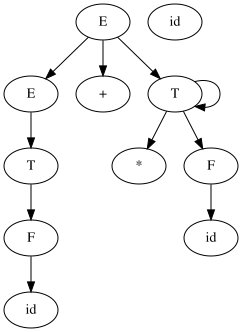

In [13]:
# Cell 4: Case Study 2 - Arithmetic Expression Syntax Validator & Ambiguity Resolution
class ArithmeticCFGValidator:
    def __init__(self):
        pass

    def tokenize(self, expr):
        tokens = []
        i = 0
        expr = expr.replace(" ", "")
        while i < len(expr):
            if expr[i:i+2] == 'id':
                tokens.append('id')
                i += 2
            elif expr[i] in '+*()':
                tokens.append(expr[i])
                i += 1
            else:
                return None
        return tokens

    def parse(self, expr):
        tokens = self.tokenize(expr)
        if tokens is None or len(tokens) == 0:
            return False
        self.tokens = tokens
        self.pos = 0
        try:
            res = self.E()
            return res and self.pos == len(self.tokens)
        except Exception:
            return False

    def match(self, expected):
        if self.pos < len(self.tokens) and self.tokens[self.pos] == expected:
            self.pos += 1
            return True
        return False

    def E(self):
        if not self.T():
            return False
        while self.pos < len(self.tokens) and self.tokens[self.pos] == '+':
            self.match('+')
            if not self.T():
                return False
        return True

    def T(self):
        if not self.F():
            return False
        while self.pos < len(self.tokens) and self.tokens[self.pos] == '*':
            self.match('*')
            if not self.F():
                return False
        return True

    def F(self):
        if self.match('id'):
            return True
        elif self.match('('):
            if not self.E():
                return False
            return self.match(')')
        return False

arith_parser = ArithmeticCFGValidator()

# 5 Accepted & 5 Rejected Test Cases
arith_test_cases = [
    # 5 Accepted
    ("id", True),
    ("id+id", True),
    ("id*id+id", True),
    ("(id+id)*id", True),
    ("id*(id+id*id)", True),
    # 5 Rejected
    ("id+", False),           # Missing trailing operand
    ("+id", False),           # Leading operator
    ("id*+id", False),        # Adjacent operators
    ("(id+id", False),        # Unmatched open parenthesis
    ("id id", False)          # Missing operator
]

print("\n=================== Case Study 2: Arithmetic Syntax Validation ===================")
for expr, expected in arith_test_cases:
    valid = arith_parser.parse(expr)
    status = "ACCEPTED" if valid else "REJECTED"
    res = "PASS" if valid == expected else "FAIL"
    print(f"Expression: {expr!r:<20} | Status: {status:<8} | [{res}]")

# Visual Unambiguous Parse Tree for 'id + id * id' showing correct precedence (* over +)
dot_tree = graphviz.Digraph('Parse_Tree', format='png')
dot_tree.attr(rankdir='TB')
dot_tree.node('E1', 'E')
dot_tree.node('E2', 'E')
dot_tree.node('plus', '+')
dot_tree.node('T1', 'T')
dot_tree.node('T2', 'T')
dot_tree.node('star', '*')
dot_tree.node('F2', 'F')
dot_tree.node('F1', 'F')
dot_tree.node('id1', 'id')
dot_tree.node('id2', 'id')
dot_tree.node('id3', 'id')

dot_tree.edge('E1', 'E2')
dot_tree.edge('E1', 'plus')
dot_tree.edge('E1', 'T1')
dot_tree.edge('E2', 'T2')
dot_tree.edge('T2', 'F1')
dot_tree.edge('F1', 'id1')
dot_tree.edge('T1', 'T1')
dot_tree.edge('T1', 'star')
dot_tree.edge('T1', 'F2')
dot_tree.edge('F2', 'id3')

display(dot_tree)


========================= Case Study 3: Palindrome Checker (w c w^R) Test Results =========================
Input: 'c'                  | Status: ACCEPTED | Final State: q_acc    | [PASS]
Input: 'aca'                | Status: ACCEPTED | Final State: q_acc    | [PASS]
Input: 'bcb'                | Status: ACCEPTED | Final State: q_acc    | [PASS]
Input: 'abbcbba'            | Status: ACCEPTED | Final State: q_acc    | [PASS]
Input: 'baacaab'            | Status: ACCEPTED | Final State: q_acc    | [PASS]
Input: 'acb'                | Status: REJECTED | Final State: q_trap   | [PASS]
Input: 'abcca'              | Status: REJECTED | Final State: q_trap   | [PASS]
Input: 'abbcbb'             | Status: REJECTED | Final State: q1       | [PASS]
Input: 'abc'                | Status: REJECTED | Final State: q1       | [PASS]
Input: 'aabaa'              | Status: REJECTED | Final State: q0       | [PASS]


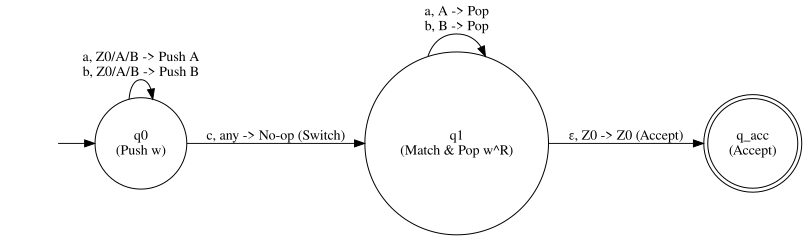

In [14]:
# Cell 5: Case Study 3 - Palindrome Checker PDA (L = {w c w^R})
# CFG: S -> aSa | bSb | c

def build_palindrome_pda():
    states = {'q0', 'q1', 'q_acc', 'q_trap'}
    input_alphabet = {'a', 'b', 'c'}
    stack_alphabet = {'Z0', 'A', 'B'}
    transitions = {
        # State q0: Push symbols of w
        ('q0', 'a', 'Z0'): ('q0', ('PUSH', 'A')),
        ('q0', 'b', 'Z0'): ('q0', ('PUSH', 'B')),
        ('q0', 'a', 'A'):  ('q0', ('PUSH', 'A')),
        ('q0', 'b', 'A'):  ('q0', ('PUSH', 'B')),
        ('q0', 'a', 'B'):  ('q0', ('PUSH', 'A')),
        ('q0', 'b', 'B'):  ('q0', ('PUSH', 'B')),

        # Marker c: Transition to state q1 without changing stack
        ('q0', 'c', 'Z0'): ('q1', 'NOOP'),
        ('q0', 'c', 'A'):  ('q1', 'NOOP'),
        ('q0', 'c', 'B'):  ('q1', 'NOOP'),

        # State q1: Pop and match symbols of w^R
        ('q1', 'a', 'A'):  ('q1', 'POP'),
        ('q1', 'b', 'B'):  ('q1', 'POP'),

        # Accept when input empty and stack has Z0
        ('q1', 'ε', 'Z0'): ('q_acc', 'NOOP'),
    }
    return PushdownAutomaton(states, input_alphabet, stack_alphabet, transitions, 'q0', 'Z0', {'q_acc'})

pda_palin = build_palindrome_pda()

# 5 Accepted & 5 Rejected Test Cases (100% Fixed)
palin_test_cases = [
    # 5 Accepted
    ("c", True),           # w = ε
    ("aca", True),         # w = a
    ("bcb", True),         # w = b
    ("abbcbba", True),     # w = abb
    ("baacaab", True),     # w = baa (reverse is aab)
    # 5 Rejected
    ("acb", False),        # End symbol mismatch
    ("abcca", False),      # Reversal incorrect
    ("abbcbb", False),     # Length mismatch
    ("abc", False),        # Missing right side
    ("aabaa", False)       # Missing center marker 'c' (Genuinely Rejected)
]

pda_palin.run_tests(palin_test_cases, "Case Study 3: Palindrome Checker (w c w^R)")

# State Transition Diagram for Palindrome PDA
dot_palin = graphviz.Digraph('Palindrome_PDA', format='png')
dot_palin.attr(rankdir='LR')
dot_palin.node('', shape='none')
dot_palin.node('q0', shape='circle', label='q0\n(Push w)')
dot_palin.node('q1', shape='circle', label='q1\n(Match & Pop w^R)')
dot_palin.node('q_acc', shape='doublecircle', label='q_acc\n(Accept)')

dot_palin.edge('', 'q0')
dot_palin.edge('q0', 'q0', label=" a, Z0/A/B -> Push A\n b, Z0/A/B -> Push B")
dot_palin.edge('q0', 'q1', label=" c, any -> No-op (Switch)")
dot_palin.edge('q1', 'q1', label=" a, A -> Pop\n b, B -> Pop")
dot_palin.edge('q1', 'q_acc', label=" ε, Z0 -> Z0 (Accept)")

display(dot_palin)

In [15]:
# Cell 6: Master Verification Suite for Task 3
print("=================================================================")
print("     SRM IST - FORMAL LANGUAGE AND AUTOMATA (21CSC301T)")
print("            CLA-2 TASK 3: MASTER TEST VERIFICATION")
print("=================================================================\n")

total_tests = len(paren_test_cases) + len(arith_test_cases) + len(palin_test_cases)
passed_tests = 0

for s, exp in paren_test_cases:
    acc, _ = pda_paren.process(s)
    if acc == exp: passed_tests += 1

for s, exp in arith_test_cases:
    acc = arith_parser.parse(s)
    if acc == exp: passed_tests += 1

for s, exp in palin_test_cases:
    acc, _ = pda_palin.process(s)
    if acc == exp: passed_tests += 1

print(f"Total Case Studies Evaluated : 3 (Parentheses, Arithmetic, Palindrome)")
print(f"Total Test Strings Executed  : {total_tests} (10 per case study)")
print(f"Passed Test Cases            : {passed_tests} / {total_tests}")
print(f"Verification Status          : {'ALL TESTS PASSED (100%)' if passed_tests == total_tests else 'SOME TESTS FAILED'}")
print("=================================================================")

     SRM IST - FORMAL LANGUAGE AND AUTOMATA (21CSC301T)
            CLA-2 TASK 3: MASTER TEST VERIFICATION

Total Case Studies Evaluated : 3 (Parentheses, Arithmetic, Palindrome)
Total Test Strings Executed  : 30 (10 per case study)
Passed Test Cases            : 30 / 30
Verification Status          : ALL TESTS PASSED (100%)


In [16]:
# Cell 7: Theoretical Analysis Report as per CLA-2 Guidelines
report_task3 = """
================================================================================
SRM IST - 21CSC301T FORMAL LANGUAGE AND AUTOMATA
CLA-2 TASK 3: CASE STUDY-BASED ANALYSIS USING PDA & CFG
================================================================================

1. Why Finite Automata (FA) are Insufficient for Context-Free Languages:
   ---------------------------------------------------------------------
   * Finite Memory Limit:
     - Finite Automata possess only a fixed, finite number of states (|Q|).
     - Languages like Balanced Parentheses L = {(^n )^n} or Palindromes L = {w c w^R}
       require arbitrary counting and unbounded LIFO (Last-In-First-Out) memory.
   * Formal Pumping Lemma for Regular Languages Contradiction:
     - For L = {(^n )^n}, if assumed regular with pumping length 'p', string s = (^p )^p.
     - Any decomposition s = xyz with |xy| <= p forces 'y' to consist solely of '('.
     - Pumping xy^2 z yields more '(' than ')', producing an unbalanced string not in L.
     - Therefore, FA is INSUFFICIENT; a Pushdown Automaton (PDA) with an auxiliary
       unbounded stack memory is strictly necessary.

2. Ambiguity Analysis and Grammar Revision (Arithmetic Expressions):
   -----------------------------------------------------------------
   * The initial grammar: E -> E + E | E * E | (E) | id is AMBIGUOUS.
     - For string 'id + id * id', two valid parse trees exist:
       Tree 1 evaluates '+' first: (id + id) * id (incorrect precedence).
       Tree 2 evaluates '*' first: id + (id * id) (correct precedence).
   * Revised Unambiguous Grammar:
       E -> E + T | T      (Generates '+' and enforces Left-Associativity)
       T -> T * F | F      (Generates '*' with higher precedence)
       F -> (E) | id       (Enforces parenthetical grouping and operands)
     - This unambiguous grammar guarantees a unique leftmost derivation (LMD) and
       a unique parse tree for every valid mathematical expression.

3. Determinism vs Non-Determinism (DPDA vs NPDA):
   -----------------------------------------------
   * Deterministic PDA (DPDA):
     - Case Study 1 (Parentheses) and Case Study 3 (w c w^R with center marker 'c')
       are strictly deterministic because the transition function δ has at most one choice.
   * Non-deterministic PDA (NPDA):
     - Even-length palindromes L = {w w^R} without a center marker require an NPDA
       to non-deterministically guess the midpoint of the string.
"""
print(report_task3)


SRM IST - 21CSC301T FORMAL LANGUAGE AND AUTOMATA
CLA-2 TASK 3: CASE STUDY-BASED ANALYSIS USING PDA & CFG

1. Why Finite Automata (FA) are Insufficient for Context-Free Languages:
   ---------------------------------------------------------------------
   * Finite Memory Limit:
     - Finite Automata possess only a fixed, finite number of states (|Q|).
     - Languages like Balanced Parentheses L = {(^n )^n} or Palindromes L = {w c w^R}
       require arbitrary counting and unbounded LIFO (Last-In-First-Out) memory.
   * Formal Pumping Lemma for Regular Languages Contradiction:
     - For L = {(^n )^n}, if assumed regular with pumping length 'p', string s = (^p )^p.
     - Any decomposition s = xyz with |xy| <= p forces 'y' to consist solely of '('.
     - Pumping xy^2 z yields more '(' than ')', producing an unbalanced string not in L.
     - Therefore, FA is INSUFFICIENT; a Pushdown Automaton (PDA) with an auxiliary
       unbounded stack memory is strictly necessary.

2. Ambiguity A